# 10 · Field test: one real wall crack, repeated captures (supplementary)

A VisionCrack label printed on clear film is stuck over a real crack in a painted wall.
The crack runs straight through the label. The capture app (`mobile/`) took **20 photos** of the same spot, each one auto-captured when the gates passed.

This notebook
1. measures every photo: label pose, keystone, sharpness, barcode decode, scale and crack width;
2. **selects 10 photos using capture quality only**. The crack width is never used to choose, so the selection cannot pull the result toward any value;
3. reports the repeatability of the crack width for the 10 selected photos and, for transparency, for all 20.

| | |
|---|---|
| **Inputs** | `data/raw/images/` (10 photos kept for the dataset) + `data/sample/data/` (the other 10); 3024 × 4032, no EXIF / GPS |
| **Outputs** | `results/tables/field_crack_all.csv`, `field_crack_selected.csv`, `field_crack_summary.csv`; `results/figures/field_*.png` |
| **Runtime** | ~20 s |

**Precision only.** This notebook gives **repeatability** over 3–13 mm above the label. A manual reference reading at one point
(0.45 mm, 7–9 mm above the label frame) is compared with the app in notebook 12.

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import numpy as np, pandas as pd, matplotlib.pyplot as plt, dataclasses
from scipy import stats
import visioncrack as vc
from visioncrack import io, field
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

# The 10 photos the author kept are in the dataset (data/raw/images); the other 10 stay in data/sample/data.
DATASET_DIR = io.data_dir() / 'images'
EXTRA_DIR = io.repo_root() / 'data' / 'sample' / 'data'
N_SELECT = 10
files = sorted(list(DATASET_DIR.glob('VisionCrack_*.JPG')) + list(EXTRA_DIR.glob('VisionCrack_*.JPG')),
               key=lambda p: p.name)          # file name = capture time, so photo 1..20 is capture order
in_dataset = {p.name for p in DATASET_DIR.glob('VisionCrack_*.JPG')}
print(len(files), 'photos;', len(in_dataset), 'in the dataset')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0
20 photos; 10 in the dataset


## 1 · What is measured

**Scale from the barcode, not from the frame.** The bars are read from a *row-median* profile of the de-rotated label.
The crack crosses the barcode, but it is wavy and sits in any one column for only a few rows, so the median removes it.
(A per-row reader finds 19–20 bars instead of 18, because the 0.5 mm crack looks like a 0.5 mm bar.)

Printed bars come out wider than nominal by a constant amount (ink spread). The scale is therefore the **slope** of
`bar px = bar mm / s + offset` over the 18 bars of the decoded label; the offset absorbs the ink spread.

**Crack band.** The crack is measured **3–13 mm above the red frame's top edge**. The band is set in mm (using each photo's own scale),
so every photo measures the same piece of crack. Per row, the crack is tracked, cut at half height between paper and crack
(sub-pixel, the same edge rule as the bars) and corrected for the local crack direction. The photo's value is the **median over the band's rows**.

In [ ]:
rs = [field.measure_field(f) for f in files]
df = pd.DataFrame([{k: v for k, v in dataclasses.asdict(r).items() if k not in ('rows_mm', 'rows_y_mm')} for r in rs])
df.insert(0, 'photo', np.arange(1, len(df) + 1))
df['in_dataset'] = df.file.isin(in_dataset)
df['keystone_pct'] = 100 * np.maximum(abs(df.tb_ratio - 1), abs(df.lr_ratio - 1))
df['frame_err_mm'] = abs(df.frame_w_mm - vc.constants.LABEL_WIDTH_MM)
show = ['photo', 'file', 'angle_deg', 'keystone_pct', 'sharpness', 'code', 'scale', 'ink_spread_px',
        'frame_w_mm', 'crack_px', 'crack_mm', 'crack_mm_label', 'valid_rows']
df[show].round(4)

,photo,file,angle_deg,keystone_pct,sharpness,code,scale,ink_spread_px,frame_w_mm,crack_px,crack_mm,crack_mm_label,valid_rows
0,1,VisionCrack_1793160054973.JPG,0.1805,0.6084,239.0395,3lAy,0.0587,2.4061,50.1435,8.7132,0.5112,0.5098,1.0
1,2,VisionCrack_1793160064902.JPG,-0.2768,0.9346,236.1999,3lAy,0.0578,2.5213,50.1711,8.8253,0.5098,0.5080,1.0
2,3,VisionCrack_1793160076169.JPG,-0.1063,0.4042,302.1251,3lAy,0.0589,2.3257,50.0636,8.6765,0.5114,0.5108,1.0
3,4,VisionCrack_1793160083161.JPG,0.0000,0.7889,257.4512,3lAy,0.0579,2.3509,50.0367,8.8164,0.5106,0.5102,1.0
4,5,VisionCrack_1793160088942.JPG,-0.3951,1.2135,184.8606,3lAy,0.0596,2.4045,50.1684,8.8958,0.5303,0.5285,1.0
5,6,VisionCrack_1793160092679.JPG,-0.1939,0.9357,245.5170,3lAy,0.0578,2.5280,50.1752,8.9254,0.5158,0.5140,1.0
6,7,VisionCrack_1793160100977.JPG,-0.1473,0.7720,275.9412,3lAy,0.0571,2.5752,50.2557,8.9359,0.5107,0.5081,1.0
7,8,VisionCrack_1793160110719.JPG,0.0000,0.8314,213.2314,3lAy,0.0587,2.4496,50.2268,8.7876,0.5162,0.5139,1.0
8,9,VisionCrack_1793160116071.JPG,-0.1209,0.6147,187.9935,3lAy,0.0597,2.5192,50.3486,8.7392,0.5214,0.5178,1.0
9,10,VisionCrack_1793160121747.JPG,0.0000,0.9481,249.1454,3lAy,0.0584,2.4281,50.2441,8.8806,0.5182,0.5157,1.0


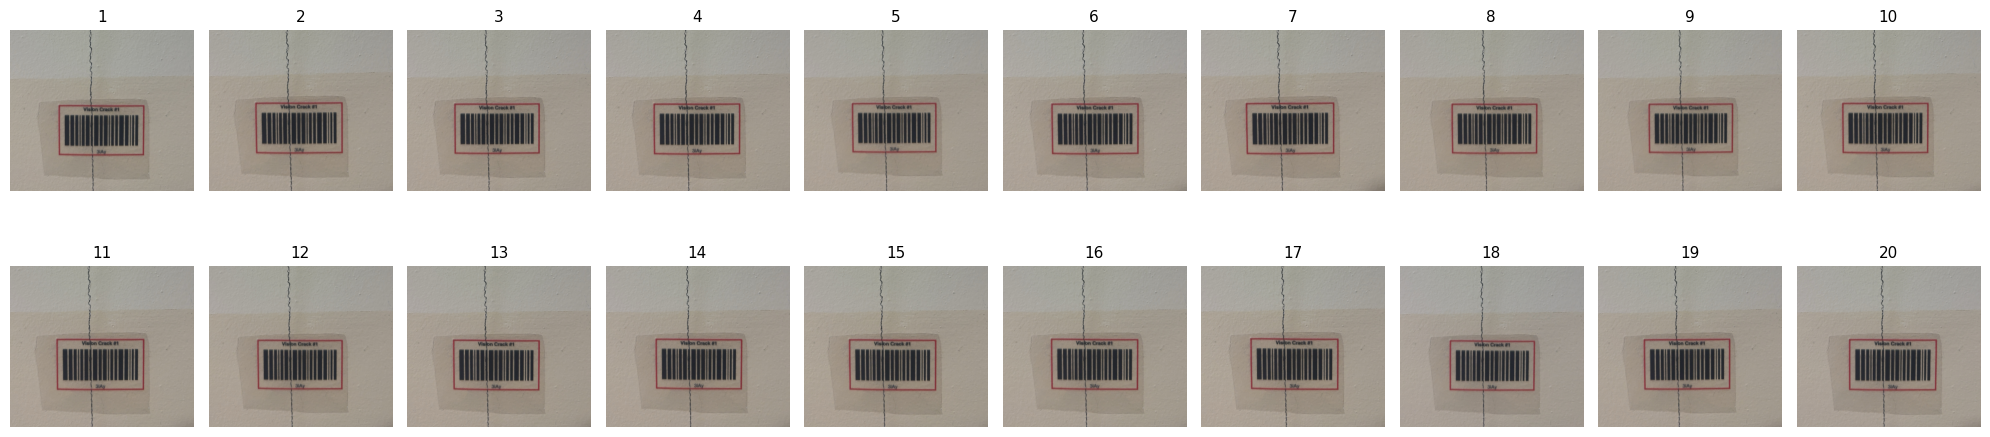

In [ ]:
# All 20 photos, label region, numbered as in the table
import cv2
fig, axes = plt.subplots(2, 10, figsize=(20, 5.4))
for ax, f, r in zip(axes.ravel(), files, df.itertuples()):
    img = vc.read_rgb(f)
    ax.imshow(cv2.resize(img[2300:3900, 600:2424], (456, 400)))
    ax.set_title(f'{r.photo}', fontsize=11); ax.axis('off')
plt.tight_layout(); plt.savefig(FIG / 'field_all_photos.png', dpi=150); plt.show()

## 2 · Selection rule (fixed before looking at crack widths)

**Hard checks** (a photo failing any is dropped):
* label found, barcode decodes to the expected payload, 18 bars;
* |in-plane angle| < 2° (paper gate τθ);
* keystone (largest edge-length mismatch of the red frame) < 2 %.

**Ranking** of the photos that pass, best first, by the sum of three ranks:
| metric | why it matters for width | better |
|---|---|---|
| sharpness (variance of the Laplacian on the label) | blur spreads a 9-px crack and widens the half-height cut | higher |
| keystone % | out-of-plane tilt stretches one side of the image | lower |
| \|frame width − 50 mm\| using the barcode scale | checks the scale on an independent length (the printed frame) | lower |

The top `N_SELECT` = 10 are kept. Ties are broken by sharpness.

In [ ]:
EXPECTED_CODE = df.code.mode()[0]          # the label's payload ('3lAy' for this label)
hard = pd.DataFrame({
    'label': df.label_found,
    'decode': df.decode_ok & (df.code == EXPECTED_CODE) & (df.n_bars == 18),
    'angle<2°': df.angle_deg.abs() < vc.constants.ROTATION_MAX_DEG,
    'keystone<2%': df.keystone_pct < 2.0,
})
df['passes'] = hard.all(axis=1)
ok = df[df.passes].copy()
ok['rank_sharp'] = ok.sharpness.rank(ascending=False)
ok['rank_keystone'] = ok.keystone_pct.rank()
ok['rank_frame'] = ok.frame_err_mm.rank()
ok['score'] = ok.rank_sharp + ok.rank_keystone + ok.rank_frame
ok = ok.sort_values(['score', 'sharpness'], ascending=[True, False])
selected = ok.head(N_SELECT).sort_values('photo')
df['selected'] = df.photo.isin(selected.photo)

print('expected payload:', EXPECTED_CODE, '| pass hard checks:', int(df.passes.sum()), 'of', len(df))
print('selected photos :', selected.photo.tolist())
print('dropped photos  :', df.loc[~df.selected, 'photo'].tolist())
print('author dataset  :', df.loc[df.in_dataset, 'photo'].tolist(), '(data/raw/images, used in notebook 11)')
ok[['photo', 'sharpness', 'keystone_pct', 'frame_err_mm', 'rank_sharp', 'rank_keystone', 'rank_frame', 'score']].round(3)

expected payload: 3lAy | pass hard checks: 20 of 20
selected photos : [1, 3, 4, 7, 11, 14, 15, 17, 18, 20]
dropped photos  : [2, 5, 6, 8, 9, 10, 12, 13, 16, 19]
author dataset  : [1, 2, 3, 4, 7, 11, 13, 16, 17, 18] (data/raw/images, used in notebook 11)


,photo,sharpness,keystone_pct,frame_err_mm,rank_sharp,rank_keystone,rank_frame,score
2,3,302.125,0.404,0.064,1.0,1.0,3.0,5.0
3,4,257.451,0.789,0.037,4.0,9.0,2.0,15.0
19,20,255.603,0.698,0.152,5.0,7.0,7.0,19.0
17,18,240.221,0.607,0.097,12.0,3.0,4.0,19.0
10,11,226.848,0.696,0.034,15.0,6.0,1.0,22.0
0,1,239.040,0.608,0.143,13.0,4.0,6.0,23.0
6,7,275.941,0.772,0.256,2.0,8.0,15.0,25.0
16,17,258.283,0.925,0.267,3.0,12.0,16.0,31.0
14,15,244.468,0.465,0.405,10.0,2.0,20.0,32.0
13,14,241.802,0.827,0.225,11.0,10.0,11.0,32.0


## 3 · Results

`r` is the **repeatability limit** of ISO 5725-6, r = 2.77 · SD: two photos of the same crack differ by less than r in 95 % of cases.
`CI95` is the 95 % t-interval of the mean.

In [ ]:
def summary(x):
    x = np.asarray(x, float); n = len(x); m, s = x.mean(), x.std(ddof=1)
    h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    return pd.Series({'n': n, 'mean_mm': m, 'sd_mm': s, 'cv_pct': 100 * s / m,
                      'ci95_lo': m - h, 'ci95_hi': m + h, 'r_2.77sd_mm': 2.77 * s,
                      'min_mm': x.min(), 'max_mm': x.max(), 'range_mm': np.ptp(x)})

summ = pd.DataFrame({
    'selected 10 · barcode scale': summary(selected.crack_mm),
    'selected 10 · label-width scale': summary(selected.crack_mm_label),
    'dataset 10 (author) · barcode scale': summary(df.loc[df.in_dataset, 'crack_mm']),
    'all 20 · barcode scale': summary(df.crack_mm),
    'all 20 · label-width scale': summary(df.crack_mm_label),
}).T
summ.to_csv(TAB / 'field_crack_summary.csv', float_format='%.4f')
summ.round(4)

,n,mean_mm,sd_mm,cv_pct,ci95_lo,ci95_hi,r_2.77sd_mm,min_mm,max_mm,range_mm
selected 10 · barcode scale,10.0,0.5112,0.0031,0.6013,0.5090,0.5134,0.0085,0.5039,0.5157,0.0117
selected 10 · label-width scale,10.0,0.5094,0.0027,0.5354,0.5075,0.5114,0.0076,0.5024,0.5122,0.0098
dataset 10 (author) · barcode scale,10.0,0.5110,0.0011,0.2074,0.5102,0.5117,0.0029,0.5093,0.5131,0.0037
all 20 · barcode scale,20.0,0.5142,0.0060,1.1664,0.5113,0.5170,0.0166,0.5039,0.5303,0.0264
all 20 · label-width scale,20.0,0.5121,0.0056,1.0977,0.5095,0.5147,0.0156,0.5024,0.5285,0.0261


In [ ]:
sel = summ.loc['selected 10 · barcode scale']; allr = summ.loc['all 20 · barcode scale']
print(f"Selected 10: {sel.mean_mm:.3f} ± {sel.sd_mm:.4f} mm (CV {sel.cv_pct:.1f} %), "
      f"95 % CI {sel.ci95_lo:.3f}–{sel.ci95_hi:.3f} mm, r = {sel['r_2.77sd_mm']:.3f} mm")
print(f"All 20     : {allr.mean_mm:.3f} ± {allr.sd_mm:.4f} mm (CV {allr.cv_pct:.1f} %)")
print(f"Scale check: printed frame = {df.frame_w_mm.mean():.2f} ± {df.frame_w_mm.std():.2f} mm (label spec 50 mm)")
print(f"Ink spread : {df.ink_spread_px.mean():.2f} px = {(df.ink_spread_px * df.scale).mean():.3f} mm per bar")

Selected 10: 0.511 ± 0.0031 mm (CV 0.6 %), 95 % CI 0.509–0.513 mm, r = 0.009 mm
All 20     : 0.514 ± 0.0060 mm (CV 1.2 %)
Scale check: printed frame = 50.20 ± 0.10 mm (label spec 50 mm)
Ink spread : 2.48 px = 0.144 mm per bar


## 4 · Per-photo values

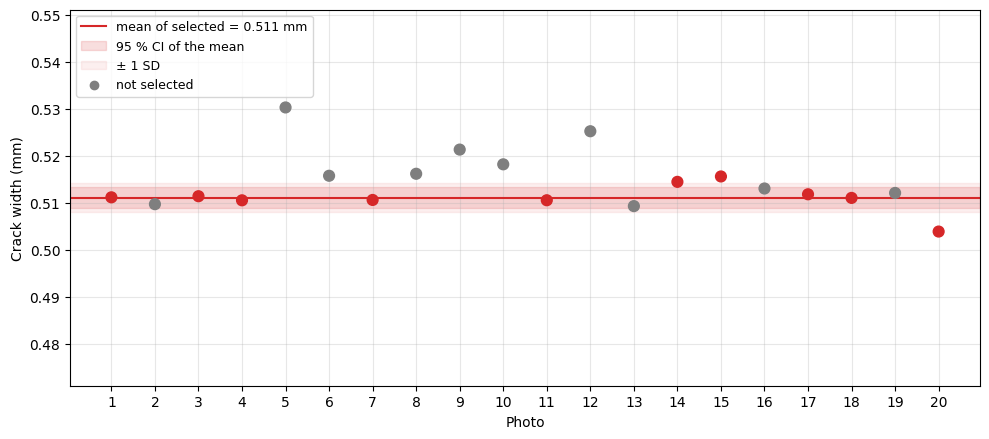

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
c = np.where(df.selected, 'tab:red', 'tab:gray')
ax.scatter(df.photo, df.crack_mm, c=c, s=60, zorder=3)
ax.axhline(sel.mean_mm, color='tab:red', lw=1.5, label=f'mean of selected = {sel.mean_mm:.3f} mm')
ax.axhspan(sel.ci95_lo, sel.ci95_hi, color='tab:red', alpha=.15, label='95 % CI of the mean')
ax.axhspan(sel.mean_mm - sel.sd_mm, sel.mean_mm + sel.sd_mm, color='tab:red', alpha=.07, label='± 1 SD')
ax.scatter([], [], c='tab:gray', label='not selected')
ax.set_xticks(df.photo); ax.set_xlabel('Photo'); ax.set_ylabel('Crack width (mm)')
ax.set_ylim(sel.mean_mm - 0.04, sel.mean_mm + 0.04); ax.grid(alpha=.3); ax.legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'field_per_photo.png', dpi=300); plt.show()

## 5 · Is the selection rule sensible? Sharpness vs. width

Shown *after* the selection, as a check of the rule, not as an input to it.
If blur widens the measured crack, the least sharp photos should read wider.

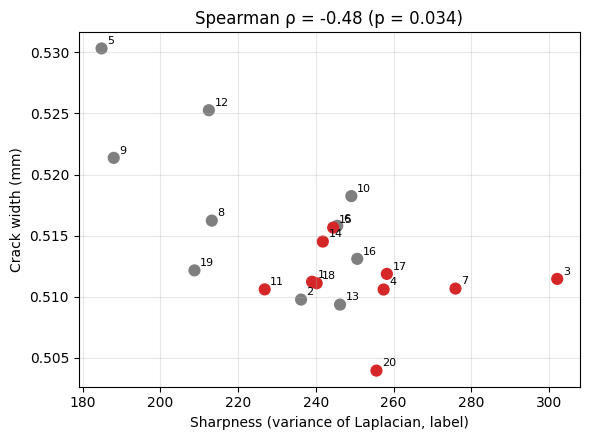

In [ ]:
rho, p = stats.spearmanr(df.sharpness, df.crack_mm)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(df.sharpness, df.crack_mm, c=c, s=60)
for r in df.itertuples():
    ax.annotate(str(r.photo), (r.sharpness, r.crack_mm), xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('Sharpness (variance of Laplacian, label)'); ax.set_ylabel('Crack width (mm)')
ax.set_title(f'Spearman ρ = {rho:.2f} (p = {p:.3f})'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / 'field_sharpness_vs_width.png', dpi=300); plt.show()

## 6 · Same piece of crack in every photo

Per-row width along the band, with the row position in mm above the frame top. If the photos really measure the same crack,
the curves follow the same shape (the crack's own width changes along its length).

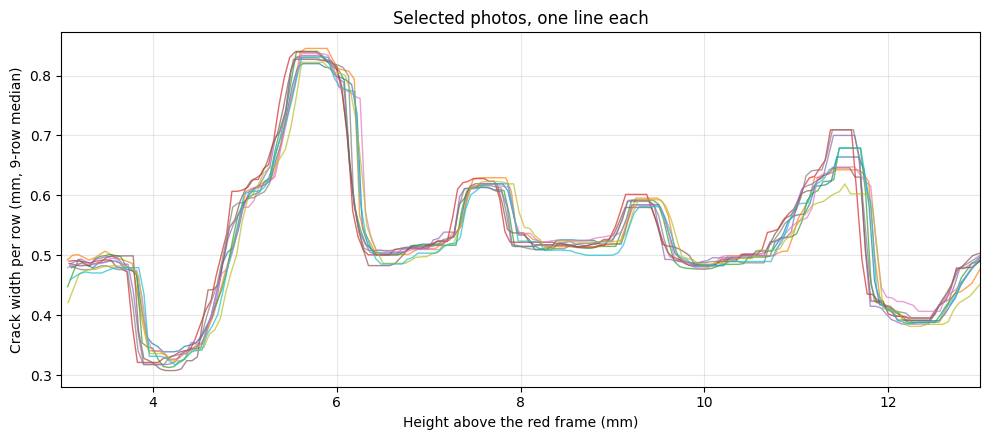

Along the crack the width varies by SD ≈ 0.122 mm; between photos the band median varies by SD = 0.0031 mm.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for r, row in zip(rs, df.itertuples()):
    if row.selected:
        y = pd.Series(r.rows_mm).rolling(9, center=True, min_periods=1).median()
        ax.plot(r.rows_y_mm, y, lw=1, alpha=.7)
ax.set_xlabel('Height above the red frame (mm)'); ax.set_ylabel('Crack width per row (mm, 9-row median)')
ax.set_xlim(*field.BAND_MM); ax.grid(alpha=.3); ax.set_title('Selected photos, one line each')
plt.tight_layout(); plt.savefig(FIG / 'field_profiles.png', dpi=300); plt.show()
row_sd = df.loc[df.selected, 'crack_row_sd_mm'].mean()
print(f'Along the crack the width varies by SD ≈ {row_sd:.3f} mm; between photos the band median varies by SD = {sel.sd_mm:.4f} mm.')

## 7 · Where the crack is measured (one selected photo)

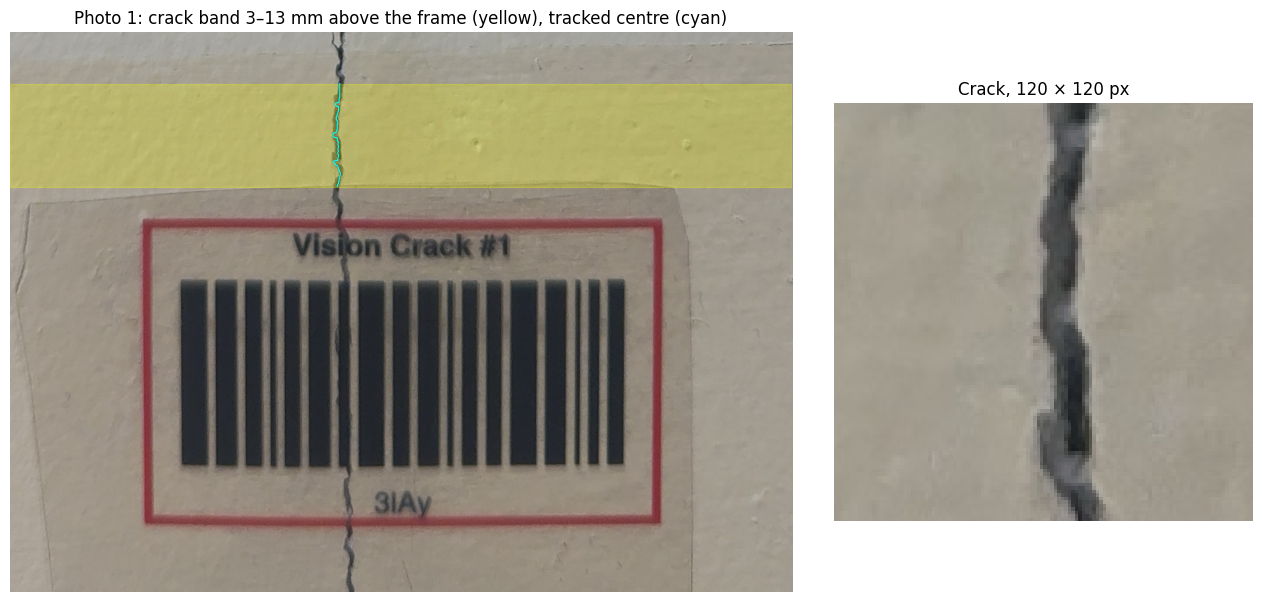

In [ ]:
k = int(selected.photo.iloc[0]) - 1
r, f = rs[k], files[k]
img = vc.read_rgb(f)
(cx, cy), (w, h), _ = field.find_red_label(img)
W, H = max(w, h), min(w, h)
rot = field.derotate(img, r.angle_deg, (cx, cy))
g = field.grey(rot)
top = int(cy - H / 2)
y0, y1 = int(top - field.BAND_MM[1] / r.scale), int(top - field.BAND_MM[0] / r.scale)
_, xs = field.crack_widths(g, int(cx - W / 2), int(cx + W / 2), y0, y1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [2, 1]})
X0, X1, Y0, Y1 = int(cx - 0.75 * W), int(cx + 0.75 * W), int(top - 0.6 * H), int(cy + 0.7 * H)
a1.imshow(rot[Y0:Y1, X0:X1]); a1.axhspan(y0 - Y0, y1 - Y0, color='yellow', alpha=.25)
a1.plot(xs - X0, np.arange(y0, y1) - Y0, color='cyan', lw=.8)
a1.set_title(f'Photo {k + 1}: crack band 3–13 mm above the frame (yellow), tracked centre (cyan)'); a1.axis('off')
yc = (y0 + y1) // 2; xc = int(xs[len(xs) // 2])
a2.imshow(rot[yc - 60:yc + 60, xc - 60:xc + 60], interpolation='nearest'); a2.set_title('Crack, 120 × 120 px'); a2.axis('off')
plt.tight_layout(); plt.savefig(FIG / 'field_band.png', dpi=200); plt.show()

## 8 · Export and summary text

In [ ]:
cols = show + ['keystone_pct', 'frame_err_mm', 'passes', 'selected', 'in_dataset']
df[list(dict.fromkeys(cols))].to_csv(TAB / 'field_crack_all.csv', index=False, float_format='%.5f')
df.loc[df.selected, list(dict.fromkeys(cols))].to_csv(TAB / 'field_crack_selected.csv', index=False, float_format='%.5f')

lab = summ.loc['selected 10 · label-width scale']
print(f"""Field repeatability. A label printed on clear film was placed over a crack in a painted wall and {len(df)} photos
were auto-captured with the app. Ten photos were selected using capture-quality criteria only (gates, keystone < 2 %,
sharpness and the printed-frame length check), without reference to the measured width. The crack width 3–13 mm above
the label was {sel.mean_mm:.3f} ± {sel.sd_mm:.3f} mm (mean ± SD, n = 10; CV {sel.cv_pct:.1f} %; 95 % CI of the mean
{sel.ci95_lo:.3f}–{sel.ci95_hi:.3f} mm; repeatability limit r = 2.77 SD = {sel['r_2.77sd_mm']:.3f} mm). With all {len(df)} photos
the result was {allr.mean_mm:.3f} ± {allr.sd_mm:.3f} mm. The barcode-derived scale put the printed 50 mm frame at
{df.frame_w_mm.mean():.2f} ± {df.frame_w_mm.std():.2f} mm, and the label-width scale (Eq. 10) gave {lab.mean_mm:.3f} ± {lab.sd_mm:.3f} mm
for the same crack.""")

Field repeatability. A label printed on clear film was placed over a crack in a painted wall and 20 photos
were auto-captured with the app. Ten photos were selected using capture-quality criteria only (gates, keystone < 2 %,
sharpness and the printed-frame length check), without reference to the measured width. The crack width 3–13 mm above
the label was 0.511 ± 0.003 mm (mean ± SD, n = 10; CV 0.6 %; 95 % CI of the mean
0.509–0.513 mm; repeatability limit r = 2.77 SD = 0.009 mm). With all 20 photos
the result was 0.514 ± 0.006 mm. The barcode-derived scale put the printed 50 mm frame at
50.20 ± 0.10 mm, and the label-width scale (Eq. 10) gave 0.509 ± 0.003 mm
for the same crack.


### Limitations
* **One reference reading.** The crack was read by hand at one point only (notebook 12). A crack microscope, or several
  card readings along 3–13 mm above the label, would give a firmer reference.
* One crack, one phone, one session and one lighting condition. Between-day and between-phone variation are not included.
* The crack (~0.5 mm, ~9 px) is close to the narrowest barcode class. It is measured with half-height sub-pixel edges,
  not with the 6-px run filter of the Table 1 pipeline.
* The photos came from the phone's Photos library, so the app's JSON sidecars (ROI, gate values) are not included.